# Quantum Circuit Simulator - a statevector engine built from scratch

**Level:** introductory / intermediate.  **Cross-check library:** Qiskit, used only in the
final section.

Everything before Part 9 is NumPy plus the Python standard library.  We build, in order:
state vectors and the Born rule, the gate matrices, a tensor-contraction engine that applies
a gate to arbitrary qubits without ever forming a `2^n x 2^n` matrix, a fluent `Circuit`
class with an ASCII drawer, projective measurement including collapse, density matrices and
the Bloch sphere, partial traces with entanglement measures, then Bell pairs and GHZ states.

**Demonstrates:** that a quantum circuit is just linear algebra executed in a fixed index
convention, that the interesting physics (interference, entanglement, the difference between
a Bell pair and a classical coin flip) lives entirely in the amplitudes and the off-diagonal
terms, and that a ~400-line from-scratch simulator reproduces Qiskit to 1e-9.

Run it top to bottom with `Runtime > Run all`; no setup, no files, no internet needed until
the last two cells.  Sections: math warm-up, states, gates, engine, circuit API, measurement,
interference, Bloch sphere, entanglement, an 88-check self-test suite, Qiskit cross-check,
recap and exercises.

---
## Part 0 - the two pieces of math that actually matter

A qubit amplitude is a complex number, so its **magnitude** sets the probability and its
**phase** sets how that amplitude interferes with others later.  `abs(z * exp(i*phi)) == abs(z)`
says phase is invisible to probability; Part 6 shows it is very visible to a Hadamard.

The tensor product `kron` is how independent systems combine: `|0> tensor |1> = |01>`, and
one qubit in superposition tensored with another in a definite state gives a two-qubit
superposition.  Throughout this notebook **qubit 0 is the leftmost (most significant) bit**,
so `|10>` means qubit 0 is 1 and qubit 1 is 0.  Qiskit uses the opposite convention; Part 9
converts.

In [1]:
import cmath
import math

import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

rng = np.random.default_rng(42)

a, b = 3 + 4j, cmath.exp(1j * math.pi / 3)
print("a              =", a)
print("|a|            =", abs(a))
print("a * e^(i pi/3) =", f"{a * b:.4f}")
print("magnitude is unchanged by a phase:", math.isclose(abs(a * b), abs(a)))

# Tensor product: how two 1-qubit states become a 2-qubit state.
zero = np.array([1, 0], dtype=complex)
one = np.array([0, 1], dtype=complex)
plus = (zero + one) / math.sqrt(2)
print("\nkron(|0>, |1>) =", np.kron(zero, one), " -> |01>")
print("kron(|+>, |0>) =", np.round(np.kron(plus, zero), 4), " -> superposition of |00>, |10>")

a              = (3+4j)
|a|            = 5.0
a * e^(i pi/3) = -1.9641+4.5981j
magnitude is unchanged by a phase: True

kron(|0>, |1>) = [0.+0.j 1.+0.j 0.+0.j 0.+0.j]  -> |01>
kron(|+>, |0>) = [0.7071+0.j 0.    +0.j 0.7071+0.j 0.    +0.j]  -> superposition of |00>, |10>


---
## Part 1 - states as vectors, probability as the Born rule

A state on `n` qubits is a unit vector of `2^n` complex amplitudes, one per bit string, in a
fixed index order.  `probabilities()` is `|amplitude|^2` (the Born rule); everything else in
the notebook is unitary, so it preserves the norm and probabilities always sum to 1.

The distinction worth internalising here:

* **global phase** `e^{i*phi}|psi>` changes every amplitude and changes nothing observable.
  `canonical_phase()` removes it so two vectors that describe the same physical state become
  bit-for-bit equal - that is the trick used to compare against Qiskit later.
* **relative phase** `[1,+1]` vs `[1,-1]` gives identical computational-basis probabilities
  yet is perfectly distinguishable, because the two states are orthogonal.

In [2]:
def zero_state(n: int) -> np.ndarray:
    """|00...0> for n qubits: the 2**n-vector with a 1 in the first slot."""
    psi = np.zeros(2**n, dtype=complex)
    psi[0] = 1.0
    return psi


def basis_state(bits: str) -> np.ndarray:
    """|01>, |110>, ... as a one-hot state vector. Leftmost character = qubit 0."""
    n = len(bits)
    psi = np.zeros(2**n, dtype=complex)
    psi[int(bits, 2)] = 1.0
    return psi


def norm(psi: np.ndarray) -> float:
    return float(np.linalg.norm(psi))


def normalize(psi: np.ndarray) -> np.ndarray:
    nrm = norm(psi)
    if nrm == 0:
        raise ValueError("cannot normalize the zero vector")
    return psi / nrm


def inner_product(phi: np.ndarray, psi: np.ndarray) -> complex:
    return np.vdot(phi, psi)  # conjugates the first argument


def probabilities(psi: np.ndarray) -> np.ndarray:
    """Born rule: p(k) = |amplitude of basis state k|^2."""
    p = np.abs(psi) ** 2
    return p / p.sum() if not math.isclose(p.sum(), 1.0, abs_tol=1e-12) else p


def basis_labels(n: int) -> list:
    """Ket labels matching the state vector's index order: qubit 0 is the leftmost bit."""
    return [f"|{format(k, '0' + str(n) + 'b')}⟩" for k in range(2**n)]


def canonical_phase(psi: np.ndarray) -> np.ndarray:
    """Kill the global phase: rotate so the largest-magnitude amplitude is real > 0.

    Two vectors that differ only by global phase become bit-for-bit equal, which is
    how we compare our simulator against Qiskit in Part 9.
    """
    pivot = np.argmax(np.abs(psi))
    if abs(psi[pivot]) == 0:
        return psi
    return psi * np.exp(-1j * np.angle(psi[pivot]))


print("|0> =", zero_state(1), "|1> =", basis_state("1"))
print("norm check:", math.isclose(norm(zero_state(3)), 1.0))
two = normalize(np.array([1, 1], dtype=complex))
print("unnormalised [1,1] ->", np.round(two, 4), "norm", norm(two))
print("probabilities of |+>:", np.round(probabilities(two), 4))
print("<+|+> =", inner_product(two, two), "  <+|0> =", f"{inner_product(two, zero_state(1)):.4f}")

phase_only = np.exp(1j * 1.1) * two
print("\nglobal phase e^{i1.1} changes the vector:", np.round(phase_only, 4))
print("but not the physics:", np.allclose(probabilities(phase_only), probabilities(two)))
print("and |<psi|e^{iphi}psi>| =", round(abs(inner_product(two, phase_only)), 6), "(same state)")
print("canonical_phase strips it back off:", np.round(canonical_phase(phase_only), 4))

# Relative phase does matter:
minus = np.array([1, -1], dtype=complex) / math.sqrt(2)
print("relative phase -> same Z-basis probs:", probabilities(two).round(3), probabilities(minus).round(3))
print("...yet orthogonal:", round(abs(inner_product(two, minus)), 8), "= 0, so perfectly distinguishable")
print("labels for 2 qubits:", basis_labels(2))

|0> = [1.+0.j 0.+0.j] |1> = [0.+0.j 1.+0.j]
norm check: True
unnormalised [1,1] -> [0.7071+0.j 0.7071+0.j] norm 0.9999999999999999
probabilities of |+>: [0.5 0.5]
<+|+> = (0.9999999999999998+0j)   <+|0> = 0.7071+0.0000j

global phase e^{i1.1} changes the vector: [0.3207+0.6302j 0.3207+0.6302j]
but not the physics: True
and |<psi|e^{iphi}psi>| = 1.0 (same state)
canonical_phase strips it back off: [0.7071-0.j 0.7071-0.j]
relative phase -> same Z-basis probs: [0.5 0.5] [0.5 0.5]
...yet orthogonal: 0.0 = 0, so perfectly distinguishable
labels for 2 qubits: ['|00⟩', '|01⟩', '|10⟩', '|11⟩']


---
## Part 2 - gates are unitary matrices

`X` flips, `Z` puts a minus sign on `|1>`, `H` moves between the two bases, `S` and `T` are
`Z^{1/2}` and `Z^{1/4}`, and `Rx/Ry/Rz` are the continuous rotations.  Unitarity
(`U^dagger U = I`) is the only requirement a gate must satisfy - `is_unitary()` checks it, and
it is what guarantees probability conservation.

Two identities pay for the rest of the notebook: `H Z H = X` (a phase between the arms of a
superposition becomes a bit flip when you recombine them - interference, Part 6) and
`H H = I`, `X^2 = Y^2 = Z^2 = I`.

`cnot_matrix()` builds the two-qubit gate as the **permutation** it performs on basis states
rather than by writing out a matrix: flip the target bit exactly when the control bit is 1.
The same construction works for any number of qubits and any control/target pair.

In [3]:
def _mat(rows) -> np.ndarray:
    return np.array(rows, dtype=complex)


I2 = _mat([[1, 0], [0, 1]])
X = _mat([[0, 1], [1, 0]])
Y = _mat([[0, -1j], [1j, 0]])
Z = _mat([[1, 0], [0, -1]])
S = _mat([[1, 0], [0, 1j]])  # Z^{1/2}
T = _mat([[1, 0], [0, cmath.exp(1j * math.pi / 4)]])  # Z^{1/4}
H = (1 / math.sqrt(2)) * _mat([[1, 1], [1, -1]])


def rx(theta: float) -> np.ndarray:
    c, s = math.cos(theta / 2), math.sin(theta / 2)
    return _mat([[c, -1j * s], [-1j * s, c]])


def ry(theta: float) -> np.ndarray:
    c, s = math.cos(theta / 2), math.sin(theta / 2)
    return _mat([[c, -s], [s, c]])


def rz(theta: float) -> np.ndarray:
    return _mat([[cmath.exp(-1j * theta / 2), 0], [0, cmath.exp(1j * theta / 2)]])


def phase(lam: float) -> np.ndarray:
    return _mat([[1, 0], [0, cmath.exp(1j * lam)]])


def cnot_matrix(n: int, control: int, target: int) -> np.ndarray:
    """The full 2**n x 2**n CNOT, built from the basis permutation it performs.

    Big-endian bit strings: qubit q is bit (n-1-q). |bits> -> |bits with target flipped>
    whenever the control bit is 1.
    """
    dim = 2**n
    M = np.zeros((dim, dim), dtype=complex)
    flip = 1 << (n - 1 - target)
    for col in range(dim):
        bit_c = (col >> (n - 1 - control)) & 1
        row = col ^ flip if bit_c else col
        M[row, col] = 1.0
    return M


def is_unitary(M: np.ndarray, tol: float = 1e-10) -> bool:
    return np.allclose(M.conj().T @ M, np.eye(M.shape[0]), atol=tol)


for name, M in [("X", X), ("Y", Y), ("Z", Z), ("H", H), ("S", S), ("T", T),
                ("Rx(pi/2)", rx(math.pi / 2)), ("Ry(pi/2)", ry(math.pi / 2)), ("Rz(pi/3)", rz(math.pi / 3))]:
    print(f"{name:>9} unitary={is_unitary(M)}  shape={M.shape}")

print("\nX as a matrix:\n", X)
print("X|0> =", (X @ zero_state(1)), " X|1> =", (X @ basis_state("1")))
print("H|0> =", np.round(H @ zero_state(1), 4), " = |+>   H|1> =", np.round(H @ basis_state("1"), 4), "= |->")
print("Z|+> =", np.round(Z @ (H @ zero_state(1)), 4), " = |->   (relative phase flipped)")
print("Z|0> =", Z @ zero_state(1), " Z|1> =", Z @ basis_state("1"))
print("H.H =", np.round(H @ H, 12), " -> Hadamard is its own inverse")
print("X.X =", np.round(X @ X, 12), " Z.Z =", np.round(Z @ Z, 12), " -> Pauli gates square to I")

print("\nCNOT on 2 qubits (control 0, target 1):\n", cnot_matrix(2, 0, 1).real)
print("CNOT as a permutation: |00>->|00>, |01>->|01>, |10>->|11>, |11>->|10>")
print("CNOT(2,0,1) unitary:", is_unitary(cnot_matrix(2, 0, 1)))
print("Same CNOT with the roles swapped (control 1, target 0):\n", cnot_matrix(2, 1, 0).real)

        X unitary=True  shape=(2, 2)
        Y unitary=True  shape=(2, 2)
        Z unitary=True  shape=(2, 2)
        H unitary=True  shape=(2, 2)
        S unitary=True  shape=(2, 2)
        T unitary=True  shape=(2, 2)
 Rx(pi/2) unitary=True  shape=(2, 2)
 Ry(pi/2) unitary=True  shape=(2, 2)
 Rz(pi/3) unitary=True  shape=(2, 2)

X as a matrix:
 [[0.+0.j 1.+0.j]
 [1.+0.j 0.+0.j]]
X|0> = [0.+0.j 1.+0.j]  X|1> = [1.+0.j 0.+0.j]
H|0> = [0.7071+0.j 0.7071+0.j]  = |+>   H|1> = [ 0.7071+0.j -0.7071+0.j] = |->
Z|+> = [ 0.7071+0.j -0.7071+0.j]  = |->   (relative phase flipped)
Z|0> = [1.+0.j 0.+0.j]  Z|1> = [ 0.+0.j -1.+0.j]
H.H = [[ 1.+0.j -0.+0.j]
 [-0.+0.j  1.+0.j]]  -> Hadamard is its own inverse
X.X = [[1.+0.j 0.+0.j]
 [0.+0.j 1.+0.j]]  Z.Z = [[1.+0.j 0.+0.j]
 [0.+0.j 1.+0.j]]  -> Pauli gates square to I

CNOT on 2 qubits (control 0, target 1):
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 0. 1.]
 [0. 0. 1. 0.]]
CNOT as a permutation: |00>->|00>, |01>->|01>, |10>->|11>, |11>->|10>
CNOT(2,0,1) 

---
## Part 3 - the engine: applying a gate to chosen qubits of a big register

This is the core of any statevector simulator.  Reshape the `2^n` vector into an
`n`-dimensional array with one axis of length 2 per qubit, `moveaxis` the target qubits to
the front, flatten them into a single `2^k` row index, multiply by `U`, then undo the
reshaping.  Cost is `O(2^k * 2^n)` and **no `2^n x 2^n` matrix is ever formed** - which is
why this notebook can run 4+ qubits comfortably.

`apply_unitary_reference()` does the identical job the slow, obvious way: loop over basis
states, read the amplitudes of `U` directly, and scatter into the output.  It shares no code
with the fast path, so the fact that they agree on random unitaries and random states to 1e-12
is genuine evidence rather than a tautology.  `embed_via_kron()` is the textbook
`I tensor ... tensor G tensor ... tensor I` construction, checked as a third opinion.

In [4]:
def apply_unitary(psi: np.ndarray, U: np.ndarray, targets: list, n: int) -> np.ndarray:
    """Apply U to the qubits in `targets` (targets[0] indexes U's most significant bit).

    Tensor-contraction route: no 2**n x 2**n matrix is ever formed.
    """
    k = len(targets)
    tensor = np.asarray(psi, dtype=complex).reshape([2] * n)
    tensor = np.moveaxis(tensor, targets, list(range(k)))  # target axes to the front
    tensor = tensor.reshape(2**k, -1)                      # rows = targets, cols = the rest
    tensor = U @ tensor
    tensor = tensor.reshape([2] * k + [2] * (n - k))
    tensor = np.moveaxis(tensor, list(range(k)), targets)  # undo the move
    return tensor.reshape(2**n)


def apply_unitary_reference(psi: np.ndarray, U: np.ndarray, targets: list, n: int) -> np.ndarray:
    """Same thing the slow, explicit way: loop over basis states and read off U's entries.

    Independent of the tensor-reshape trick, so agreement between the two is real evidence.
    """
    dim, k = 2**n, len(targets)
    out = np.zeros(dim, dtype=complex)
    target_masks = [n - 1 - q for q in targets]
    other_masks = [n - 1 - q for q in range(n) if q not in targets]
    for col in range(dim):
        if psi[col] == 0:
            continue
        t_index = int("".join(str((col >> m) & 1) for m in target_masks), 2)
        others = [(col >> m) & 1 for m in other_masks]
        for row in range(2**k):
            amp = U[row, t_index]
            if amp == 0:
                continue
            new = 0
            for shift, bit in zip(target_masks, [(row >> (k - 1 - j)) & 1 for j in range(k)]):
                new |= bit << shift
            for shift, bit in zip(other_masks, others):
                new |= bit << shift
            out[new] += amp * psi[col]
    return out


def embed_via_kron(gate: np.ndarray, qubit: int, n: int) -> np.ndarray:
    """Textbook embedding of a 1-qubit gate: identities on the untouched wires."""
    matrices = [gate if q == qubit else I2 for q in range(n)]
    out = np.array([[1.0 + 0j]])
    for M in matrices:
        out = np.kron(out, M)
    return out


# Prove the two engines agree, and both agree with the kron construction.
for n, targets in [(1, [0]), (2, [0]), (2, [1]), (2, [0, 1]), (2, [1, 0]), (3, [0, 2]), (3, [2, 1])]:
    k = len(targets)
    rng_t = np.random.default_rng(n * 10 + k)
    Q, R = np.linalg.qr(rng_t.normal(size=(2**k, 2**k)) + 1j * rng_t.normal(size=(2**k, 2**k)))
    U = Q * np.exp(1j * np.angle(R[0, 0]))  # a random unitary
    psi = normalize(rng_t.normal(size=2**n) + 1j * rng_t.normal(size=2**n))
    fast = apply_unitary(psi, U, targets, n)
    slow = apply_unitary_reference(psi, U, targets, n)
    assert np.allclose(fast, slow, atol=1e-12), (n, targets)
    assert math.isclose(norm(fast), 1.0, abs_tol=1e-12)
    print(f"n={n} targets={targets}: fast == reference, still normalised")

h0_on_2 = embed_via_kron(H, 0, 2)
assert np.allclose(apply_unitary(zero_state(2), H, [0], 2), h0_on_2 @ zero_state(2))
assert np.allclose(apply_unitary(zero_state(2), Z, [1], 2), embed_via_kron(Z, 1, 2) @ zero_state(2))
print("\nkron embedding matches the engine for H on qubit 0 and Z on qubit 1")
assert np.allclose(apply_unitary(zero_state(2), X, [0], 2), basis_state("10"))
print("X on qubit 0 of |00> ->", np.round(apply_unitary(zero_state(2), X, [0], 2), 6), "= |10> (leftmost bit is qubit 0)")
assert np.allclose(apply_unitary(zero_state(2), X, [1], 2), basis_state("01"))
print("X on qubit 1 of |00> ->", np.round(apply_unitary(zero_state(2), X, [1], 2), 6), "= |01>")

n=1 targets=[0]: fast == reference, still normalised
n=2 targets=[0]: fast == reference, still normalised
n=2 targets=[1]: fast == reference, still normalised
n=2 targets=[0, 1]: fast == reference, still normalised
n=2 targets=[1, 0]: fast == reference, still normalised
n=3 targets=[0, 2]: fast == reference, still normalised
n=3 targets=[2, 1]: fast == reference, still normalised

kron embedding matches the engine for H on qubit 0 and Z on qubit 1
X on qubit 0 of |00> -> [0.+0.j 0.+0.j 1.+0.j 0.+0.j] = |10> (leftmost bit is qubit 0)
X on qubit 1 of |00> -> [0.+0.j 1.+0.j 0.+0.j 0.+0.j] = |01>


---
## Part 4 - the `Circuit` class and an ASCII drawer

A circuit is a register plus a list of operations: `Circuit(2).h(0).cnot(0, 1).z(1)`.
Each method applies the gate to the live state vector and records `(glyph, qubits)` so
`draw()` can lay the circuit out afterwards, one column per operation, qubit 0 on top.
`copy()` snapshots the state, which lets later parts branch one circuit into three to compare
what a gate does.

Everything the rest of the notebook needs is on this API: `gate`/`two_qubit_gate`, the Paulis,
`H/S/T`, the rotations, `cnot`/`cz`, `probabilities`, `sample`, `measure`.

In [5]:
class Circuit:
    """A statevector circuit: n wires, all starting in |0>, evolving by unitaries."""

    def __init__(self, n: int, name: str = "circuit"):
        if n < 1:
            raise ValueError("need at least one qubit")
        self.n = n
        self.name = name
        self.state = zero_state(n)
        self.ops = []  # (glyph, [qubits]) for the drawer

    # ---- gate application -------------------------------------------------
    def gate(self, U: np.ndarray, qubit: int, glyph: str = "U"):
        self.state = apply_unitary(self.state, U, [qubit], self.n)
        self.ops.append((glyph, [qubit]))
        return self

    def two_qubit_gate(self, U: np.ndarray, qubits: list, glyph: str = "U"):
        self.state = apply_unitary(self.state, U, qubits, self.n)
        self.ops.append((glyph, list(qubits)))
        return self

    # ---- the assignment's four, plus the extras we use later --------------
    def x(self, q):
        return self.gate(X, q, "X")

    def y(self, q):
        return self.gate(Y, q, "Y")

    def z(self, q):
        return self.gate(Z, q, "Z")

    def h(self, q):
        return self.gate(H, q, "H")

    def s(self, q):
        return self.gate(S, q, "S")

    def t(self, q):
        return self.gate(T, q, "T")

    def rx(self, theta, q):
        return self.gate(rx(theta), q, f"Rx({theta:.2f})")

    def ry(self, theta, q):
        return self.gate(ry(theta), q, f"Ry({theta:.2f})")

    def rz(self, theta, q):
        return self.gate(rz(theta), q, f"Rz({theta:.2f})")

    def cnot(self, control, target):
        if control == target:
            raise ValueError("control and target must differ")
        cx = _mat([[1, 0, 0, 0],
                   [0, 1, 0, 0],
                   [0, 0, 0, 1],
                   [0, 0, 1, 0]])
        self.state = apply_unitary(self.state, cx, [control, target], self.n)
        self.ops.append(("CNOT", [control, target]))
        return self

    def cz(self, control, target):
        cz = _mat([[1, 0, 0, 0],
                   [0, 1, 0, 0],
                   [0, 0, 1, 0],
                   [0, 0, 0, -1]])
        self.state = apply_unitary(self.state, cz, [control, target], self.n)
        self.ops.append(("CZ", [control, target]))
        return self

    # ---- read-out ---------------------------------------------------------
    def probabilities(self) -> np.ndarray:
        return probabilities(self.state)

    def sample(self, shots: int, seed: int = None) -> dict:
        return sample_counts(self.state, self.n, shots, seed)

    def measure(self, qubits: list = None, seed: int = None):
        qubits = list(range(self.n)) if qubits is None else list(qubits)
        bits, collapsed = measure_qubits(self.state, self.n, qubits, seed)
        self.state = collapsed
        return bits

    def copy(self) -> "Circuit":
        other = Circuit(self.n, self.name)
        other.state = self.state.copy()
        other.ops = list(self.ops)
        return other

    def __repr__(self):
        return f"<Circuit {self.name!r} n={self.n} ops={len(self.ops)}>"

    def draw(self) -> str:
        return draw_circuit(self)


def draw_circuit(circ: Circuit) -> str:
    """ASCII circuit diagram, one column per operation, qubit 0 on top."""
    cols = [[] for _ in range(circ.n)]
    for glyph, qubits in circ.ops:
        boxes = {}
        if glyph == "CNOT":
            boxes[qubits[0]] = "o"
            boxes[qubits[1]] = "+"
            lo, hi = min(qubits), max(qubits)
        elif glyph == "CZ":
            boxes[qubits[0]] = boxes[qubits[1]] = "z"
            lo, hi = min(qubits), max(qubits)
        else:
            label = glyph if len(glyph) <= 6 else glyph[:6]
            for q in qubits:
                boxes[q] = label
            lo, hi = min(qubits), max(qubits)
        width = max(len(v) for v in boxes.values()) + 2
        for q in range(circ.n):
            if q in boxes:
                cols[q].append(boxes[q].center(width))
            elif lo < q < hi:
                cols[q].append("|".center(width))
            else:
                cols[q].append("-" * width)
    lines = []
    for q in range(circ.n):
        lines.append(f"q{q}: |0> -" + "-".join(cols[q]) + "-")
    return f"{circ.name}\n" + "\n".join(lines)


demo = Circuit(2, "demo").h(0).cnot(0, 1).z(1)
print(demo.draw())
print(demo, "state =", np.round(demo.state, 4))

demo
q0: |0> - H - o -----
q1: |0> ----- + - Z -
<Circuit 'demo' n=2 ops=3> state = [ 0.7071+0.j  0.    +0.j  0.    +0.j -0.7071+0.j]


---
## Part 5 - measurement: sampling, projection, collapse

`sample_counts()` draws bit strings from `|amplitude|^2` - the statistics of many runs.
`measure_qubits()` is the single-run event: pick an outcome with the Born weight, then
**project** the state onto the subspace consistent with that outcome and renormalise.  The
post-measurement state is what any later operation sees, so a repeated measurement of the
same qubit returns the same bit - collapse is idempotent, and the cell proves it.

`measure_in_basis()` handles the non-computational bases by rotating first: `H` brings the
X-basis onto `|0>/|1>`, `H S^dagger` does the Y-basis.  Measuring in a rotated basis is the
whole trick behind Bell tests and quantum key distribution.

In [6]:
def sample_counts(psi: np.ndarray, n: int, shots: int, seed: int = None) -> dict:
    """Draw `shots` bit strings from |amplitude|^2. Returns {'01': 483, ...}."""
    gen = np.random.default_rng(seed) if seed is not None else rng
    p = probabilities(psi)
    drawn = gen.choice(len(p), size=shots, p=p)
    counts = {}
    for k in drawn:
        key = format(k, f"0{n}b")
        counts[key] = counts.get(key, 0) + 1
    return dict(sorted(counts.items(), key=lambda kv: -kv[1]))


def state_from_bits(bits: str, n: int) -> np.ndarray:
    """One-hot state for a full n-qubit bit string; `bits` may be shorter if zero-padded left."""
    idx = int(bits.rjust(n, "0"), 2)
    psi = np.zeros(2**n, dtype=complex)
    psi[idx] = 1.0
    return psi


def project(psi: np.ndarray, n: int, qubits: list, bits: str) -> np.ndarray:
    """Un-normalised projection onto the subspace where `qubits` equal `bits`."""
    out = np.zeros_like(psi)
    mask = [(q, int(b)) for q, b in zip(qubits, bits)]
    for k in range(2**n):
        if all(((k >> (n - 1 - q)) & 1) == want for q, want in mask):
            out[k] = psi[k]
    return out


def measure_qubits(psi: np.ndarray, n: int, qubits: list, seed: int = None):
    """Projective measurement of `qubits` in the computational basis.

    Returns (bit_string, post-measurement state). Which branch you get is drawn from the
    Born rule; the state you get back is the projected, renormalised one.
    """
    gen = np.random.default_rng(seed) if seed is not None else rng
    weights = np.array([norm(project(psi, n, qubits, format(i, f"0{len(qubits)}b"))) ** 2
                       for i in range(2 ** len(qubits))])
    choice = gen.choice(len(weights), p=weights / weights.sum())
    bits = format(choice, f"0{len(qubits)}b")
    collapsed = project(psi, n, qubits, bits)
    return bits, normalize(collapsed)


def measure_in_basis(psi: np.ndarray, n: int, qubits: list, basis: str, seed: int = None):
    """Measure in the X or Y basis by rotating that basis onto |0>/|1>, then measuring Z.

    X: apply H (|+> -> |0>). Y: apply H S^dagger (|+i> -> |0>). Outcome bit 0 means the
    +1 eigenstate of the corresponding Pauli.
    """
    rotated = psi.copy()
    for q in qubits:
        if basis == "X":
            rotated = apply_unitary(rotated, H, [q], n)
        elif basis == "Y":
            rotated = apply_unitary(rotated, H @ S.conj().T, [q], n)
        else:
            raise ValueError("basis must be 'X', 'Y' or 'Z'")
    return measure_qubits(rotated, n, qubits, seed)


def plot_probabilities(psi: np.ndarray, n: int, title: str = "", shots: int = 0, ax=None):
    """Exact Born probabilities, optionally with sampled frequencies overlaid."""
    p = probabilities(psi)
    labels = [format(k, f"0{n}b") for k in range(2**n)]
    keep = [i for i in range(2**n) if p[i] > 1e-12]
    ax = ax or plt.subplots()[1]
    x = np.arange(len(keep))
    ax.bar(x, p[keep], width=0.62, color="#4c72b0", label="exact |amplitude|^2")
    if shots:
        counts = sample_counts(psi, n, shots, seed=1234)
        sampled = np.array([counts.get(labels[i], 0) / shots for i in keep])
        err = np.sqrt(np.maximum(sampled, 1e-12) * (1 - sampled) / shots)
        ax.errorbar(x, sampled, yerr=2 * err, fmt="o", color="#c44e52",
                    capsize=3, lw=1.4, ms=5, label=f"simulated ({shots} shots, 95% CI)")
    ax.set_xticks(x)
    ax.set_xticklabels([f"|{labels[i]}>" for i in keep])
    ax.set_ylim(0, 1.16)
    ax.set_ylabel("probability")
    ax.set_title(title or "Measurement probabilities (computational basis)", fontsize=11)
    ax.grid(axis="y", alpha=0.3)
    ax.legend(fontsize=8, loc="upper right", framealpha=0.9)
    return ax


print("sample_counts of |+>|0> over 4000 shots:", sample_counts(apply_unitary(zero_state(2), H, [0], 2), 2, 4000, seed=7))
bits, collapsed = measure_qubits(apply_unitary(zero_state(2), H, [0], 2), 2, [0], seed=3)
print("\nmeasured qubit 0 of (|00>+|10>)/sqrt2 -> got", bits, "state becomes", np.round(collapsed, 3))
print("  collapse destroyed the superposition; measuring qubit 0 again gives the same answer:",
      measure_qubits(collapsed, 2, [0], seed=99)[0] == bits)

sample_counts of |+>|0> over 4000 shots: {'00': 2013, '10': 1987}

measured qubit 0 of (|00>+|10>)/sqrt2 -> got 0 state becomes [1.+0.j 0.+0.j 0.+0.j 0.+0.j]
  collapse destroyed the superposition; measuring qubit 0 again gives the same answer: True


---
## Part 6 - interference: why relative phase is the interesting half

`|0> -H-> |+> -Z-> |->` and both give 50/50 in the computational basis - the phase is
completely invisible.  Add one more Hadamard and the two paths recombine: the `Z` version
lands on `|1>` with probability 1 while the no-`Z` version returns to `|0>`.  That is
constructive and destructive interference doing the work, and it is the mechanism every
quantum speed-up leans on.  The three panels show exact Born probabilities against sampled
frequencies with 95% confidence bars.

An X-basis measurement tells `|+>` and `|->` apart deterministically, confirming the phase is
real information - just not readable in the Z basis.

interference
q0: |0> - H -
  after H  : state [0.7071+0.j 0.7071+0.j]  Z-basis probs [0.5 0.5]
  after H,Z: state [ 0.7071+0.j -0.7071+0.j]  Z-basis probs [0.5 0.5]   <- identical statistics to |+>!
  after H,Z,H: state [0.+0.j 1.+0.j]  Z-basis probs [0. 1.]   <- the phase became a bit flip
  H alone twice: state [1.+0.j 0.+0.j]  -> back to |0>, H is its own inverse


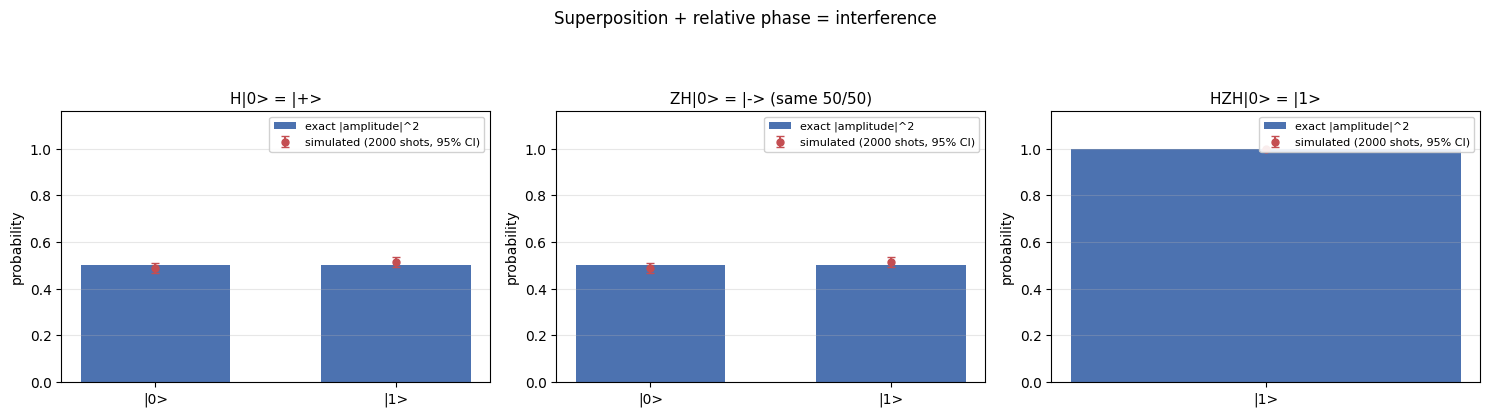


X-basis measurement tells |+> and |-> apart (bit 0 = +1 eigenvalue, bit 1 = -1):
  |+> = H|0>   -> X-basis outcome 0; Z-basis probs are the same 50/50 for both
  |-> = ZH|0>  -> X-basis outcome 1; Z-basis probs are the same 50/50 for both


In [7]:
# Superposition, step by step: |0> --H--> |+> --Z--> |-> --H--> |1>
one = Circuit(1, "interference").h(0)
print(one.draw())
print("  after H  : state", np.round(one.state, 4), " Z-basis probs", one.probabilities().round(3))

two = one.copy().z(0)
print("  after H,Z: state", np.round(two.state, 4), " Z-basis probs", two.probabilities().round(3),
      "  <- identical statistics to |+>!")

three = two.copy().h(0)
print("  after H,Z,H: state", np.round(three.state, 4), " Z-basis probs", three.probabilities().round(3),
      "  <- the phase became a bit flip")

no_z = one.copy().h(0)
print("  H alone twice: state", np.round(no_z.state, 4), " -> back to |0>, H is its own inverse")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
plot_probabilities(one.state, 1, "H|0> = |+>", 2000, axes[0])
plot_probabilities(two.state, 1, "ZH|0> = |-> (same 50/50)", 2000, axes[1])
plot_probabilities(three.state, 1, "HZH|0> = |1>", 2000, axes[2])
fig.suptitle("Superposition + relative phase = interference")
fig.tight_layout(rect=(0, 0, 1, 0.9))
plt.show()

print("\nX-basis measurement tells |+> and |-> apart (bit 0 = +1 eigenvalue, bit 1 = -1):")
for label, state in [("|+> = H|0>", one.state), ("|-> = ZH|0>", two.state)]:
    bit_x, _ = measure_in_basis(state, 1, [0], "X", seed=5)
    print(f"  {label:<12} -> X-basis outcome {bit_x}; Z-basis probs are the same 50/50 for both")

---
## Part 7 - density matrices and the Bloch sphere

Any single-qubit state is `rho = (I + x*X + y*Y + z*Z)/2`, so the three expectation values
`(<X>,<Y>,<Z>)` place it as a vector inside a unit sphere: poles are `|0>/|1>`, the equator
is the X/Y-basis states, the centre is the maximally mixed state.  Pure states sit on the
surface (`|r| = 1`), mixed states strictly inside - `|r|` is a cheap purity test.

The three panels make the gate-as-rotation picture explicit: `H` lifts a pole onto the
equator, `Z` spins it 180 degrees in longitude, `Ry(theta)` sweeps a meridian and
`H Rz(phi) H = Rx(phi)` sweeps the perpendicular one.  Two qubits need four parameters beyond
the Bloch sphere, which is why the tensor-product picture (Part 8) is the working one there.

state              r=(x,y,z)            |r|   theta   phi
|0>              (+0.000,+0.000,+1.000)  1.000    0.0    0.0
|1>              (+0.000,+0.000,-1.000)  1.000  180.0    0.0
|+> = H|0>       (+1.000,+0.000,+0.000)  1.000   90.0    0.0
|-> = ZH|0>      (-1.000,+0.000,+0.000)  1.000   90.0  180.0
|+i> = SH|0>     (+0.000,+1.000,+0.000)  1.000   90.0   90.0
|-i> = SH|1>     (+0.000,-1.000,+0.000)  1.000   90.0  270.0


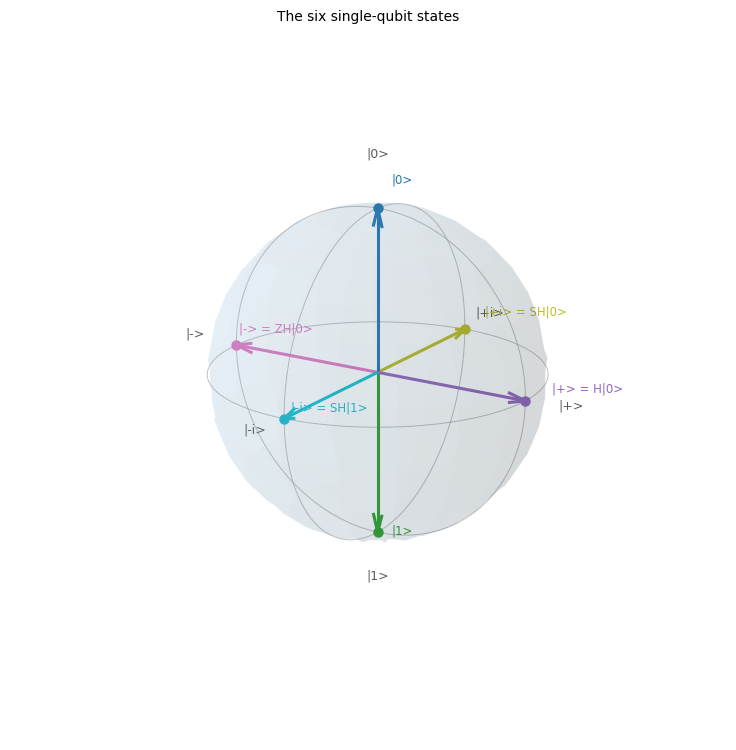

In [8]:
def density_matrix(psi: np.ndarray) -> np.ndarray:
    return np.outer(psi, np.conjugate(psi))


def bloch_from_state(psi: np.ndarray) -> np.ndarray:
    """(x, y, z) = (<X>, <Y>, <Z>) for a single qubit."""
    rho = density_matrix(psi)
    return np.array([np.real(np.trace(rho @ m)) for m in (X, Y, Z)])


def bloch_from_density(rho: np.ndarray) -> np.ndarray:
    return np.real(np.array([np.trace(rho @ m) for m in (X, Y, Z)]))


def bloch_angles(psi: np.ndarray) -> tuple:
    x, y, z = bloch_from_state(psi)
    r = math.sqrt(x * x + y * y + z * z)
    theta = math.acos(max(-1.0, min(1.0, z / r if r else 0.0)))
    phi = math.atan2(y, x) % (2 * math.pi)
    return r, theta, phi


def set_equal_axes(ax):
    lim = 1.25
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_zlim(-lim, lim)
    ax.set_box_aspect((1, 1, 1))


def draw_bloch(states, labels=None, colors=None, title="", ax=None):
    """Plot state vectors (or 2x2 density matrices) as Bloch vectors on the sphere."""
    labels = labels or [f"v{i}" for i in range(len(states))]
    colors = colors or plt.cm.tab10(np.linspace(0, 1, max(len(states), 1)))
    fig = None
    if ax is None:
        fig, ax = plt.subplots(figsize=(6.4, 6.4), subplot_kw={"projection": "3d"})

    u = np.linspace(0, 2 * math.pi, 36)
    v = np.linspace(0, math.pi, 18)
    ax.plot_surface(np.outer(np.cos(u), np.sin(v)),
                    np.outer(np.sin(u), np.sin(v)),
                    np.outer(np.ones_like(u), np.cos(v)),
                    color="#7fb3d5", alpha=0.10, linewidth=0, rstride=2, cstride=2)
    t = np.linspace(0, 2 * math.pi, 90)
    for circ in [np.stack([np.cos(t), np.sin(t), np.zeros_like(t)]),
                 np.stack([np.cos(t), np.zeros_like(t), np.sin(t)]),
                 np.stack([np.zeros_like(t), np.cos(t), np.sin(t)])]:
        ax.plot(*circ, color="0.65", lw=0.7, alpha=0.7)
    for vec, txt in [((1, 0, 0), "|+>"), ((-1, 0, 0), "|->"),
                     ((0, 0, 1), "|0>"), ((0, 0, -1), "|1>"),
                     ((0, 1, 0), "|+i>"), ((0, -1, 0), "|-i>")]:
        ax.plot([0, vec[0]], [0, vec[1]], [0, vec[2]], color="0.5", lw=0.9)
        ax.text(*(np.array(vec) * 1.3), txt, fontsize=9, color="0.35", ha="center")

    for state, label, color in zip(states, labels, colors):
        rho = state if (isinstance(state, np.ndarray) and state.shape == (2, 2)) else density_matrix(state)
        r = bloch_from_density(rho)
        ax.quiver(0, 0, 0, r[0], r[1], r[2], color=color, lw=2.2, arrow_length_ratio=0.12)
        ax.scatter(*r, color=color, s=42, zorder=5)
        if label:
            ax.text(*(r * 1.08 + 0.06), label, fontsize=8.5, color=color)

    ax.view_init(elev=18, azim=-58)
    set_equal_axes(ax)
    ax.set_title(title, pad=2, fontsize=10)
    ax.axis("off")
    return fig or ax.figure


# The six famous states, and where they land.
famous = {
    "|0>": zero_state(1),
    "|1>": basis_state("1"),
    "|+> = H|0>": H @ zero_state(1),
    "|-> = ZH|0>": Z @ H @ zero_state(1),
    "|+i> = SH|0>": S @ H @ zero_state(1),
    "|-i> = SH|1>": S @ H @ basis_state("1"),
}
print("state              r=(x,y,z)            |r|   theta   phi")
for label, psi in famous.items():
    x, y, z = bloch_from_state(psi)
    r, th, ph = bloch_angles(psi)
    print(f"{label:<17}({x:+.3f},{y:+.3f},{z:+.3f})  {r:.3f}  {math.degrees(th):5.1f}  {math.degrees(ph):5.1f}")

fig = plt.figure(figsize=(8.6, 7.6))
draw_bloch(list(famous.values()), list(famous.keys()), title="The six single-qubit states",
           ax=fig.add_subplot(projection="3d"))
plt.tight_layout()
plt.show()

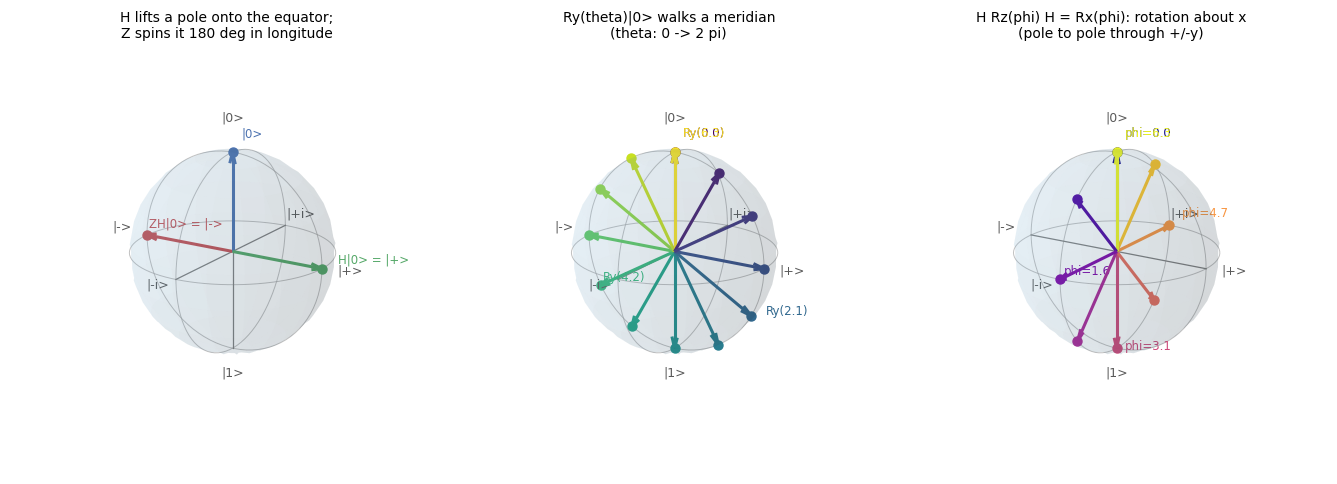

length of the Bloch vector for a pure state is 1 (on the surface):
  Ry(0.00)|0>  |r| = 1.000000
  Ry(0.70)|0>  |r| = 1.000000
  Ry(3.14)|0>  |r| = 1.000000

a mixed density matrix has |r| = 0.500 < 1 (inside the sphere)


In [9]:
# Same states, and the rotations that reach them: gates are physical rotations.
fig, axes = plt.subplots(1, 3, figsize=(17, 6.2), subplot_kw={"projection": "3d"})

draw_bloch([zero_state(1), H @ zero_state(1), Z @ H @ zero_state(1)],
           ["|0>", "H|0> = |+>", "ZH|0> = |->"], colors=["#4c72b0", "#55a868", "#c44e52"],
           title="H lifts a pole onto the equator;\nZ spins it 180 deg in longitude", ax=axes[0])

# Ry(theta) on |0> sweeps the x-z meridian: the continuous family of states.
thetas = np.linspace(0, 2 * np.pi, 13)
draw_bloch([ry(t) @ zero_state(1) for t in thetas],
           [f"Ry({t:.1f})" if i % 4 == 0 else "" for i, t in enumerate(thetas)],
           colors=[plt.cm.viridis(i / 12) for i in range(13)],
           title="Ry(theta)|0> walks a meridian\n(theta: 0 -> 2 pi)", ax=axes[1])

# H Rz(phi) H = Rx(phi): a rotation about the x-axis carries |0> down the y-z meridian.
phis = np.linspace(0, 2 * np.pi, 9)
draw_bloch([H @ rz(p) @ H @ zero_state(1) for p in phis],
           [f"phi={p:.1f}" if i % 2 == 0 else "" for i, p in enumerate(phis)],
           colors=[plt.cm.plasma(i / 8) for i in range(9)],
           title="H Rz(phi) H = Rx(phi): rotation about x\n(pole to pole through +/-y)", ax=axes[2])
fig.subplots_adjust(top=0.86, bottom=0.04, wspace=0.02)
plt.show()

print("length of the Bloch vector for a pure state is 1 (on the surface):")
for t in (0.0, 0.7, math.pi):
    r, _, _ = bloch_angles(ry(t) @ zero_state(1))
    print(f"  Ry({t:.2f})|0>  |r| = {r:.6f}")

mixed = np.array([[0.5, 0.25], [0.25, 0.5]], dtype=complex)
print(f"\na mixed density matrix has |r| = {np.linalg.norm(bloch_from_density(mixed)):.3f} < 1 (inside the sphere)")

---
## Part 8 - entanglement: the part with no classical analogue

`partial_trace()` contracts the composite density matrix down to a subsystem (via `einsum`
with a repeated index, i.e. summing the traced qubit's row and column index together).  From
it come the diagnostics used throughout the rest of the portfolio:

* `purity = Tr(rho^2)` - 1 for pure, 1/2 for a maximally mixed qubit;
* `von_neumann_entropy = -Sum p log2 p` on the eigenvalues - 1 bit for each maximally mixed
  qubit;
* `mutual_information = S(A) + S(B) - S(AB)`;
* `concurrence` for a 2-qubit pure state, 0 for separable and 1 for maximally entangled.

Bell pair: `H` then `CNOT` produces `(|00> + |11>)/sqrt(2)`, which is **random locally and
perfectly correlated globally** - each single qubit is exactly `I/2` (Bloch vector at the
centre) even though the pair is a pure state.  Contrast with `X` then `CNOT`, which is only a
classical copy, and with `CNOT` on `|0>|+>`, which stays separable.  The 300-run X-basis
correlation is the point a classically pre-agreed bit cannot reproduce.

GHZ: `(|000> + |111>)/sqrt(2)`.  Its Z-basis statistics are **identical** to a classical coin
that picks 000 or 111 - the entire difference is the coherence term at `rho[000, 111]`, visible
as the bright off-diagonal entry in the density-matrix heat map and worth 2 bits of mutual
information where the classical mixture caps at 1.

In [10]:
def partial_trace(rho: np.ndarray, keep: list, n: int) -> np.ndarray:
    """Trace out every qubit not in `keep`. Row indices a.., column indices h.."""
    keep = sorted(keep)
    row_letters, col_letters = "abcdef", "hijklm"
    ins = []
    for q in range(n):
        ins.append(row_letters[q])
    for q in range(n):
        ins.append(col_letters[q] if q in keep else row_letters[q])  # repeated letter = summed
    out = "".join(row_letters[q] for q in keep) + "".join(col_letters[q] for q in keep)
    tensor = rho.reshape([2] * (2 * n))
    return np.einsum("".join(ins) + "->" + out, tensor).reshape(2 ** len(keep), 2 ** len(keep))


def purity(rho: np.ndarray) -> float:
    return float(np.real(np.trace(rho @ rho)))


def von_neumann_entropy(rho: np.ndarray) -> float:
    eig = np.clip(np.real(np.linalg.eigvalsh(rho)), 0.0, 1.0)
    eig = eig[eig > 1e-12]
    return float(max(0.0, -np.sum(eig * np.log2(eig))))


def mutual_information(rho_ab: np.ndarray, n: int) -> float:
    s_a = von_neumann_entropy(partial_trace(rho_ab, [0], n))
    s_b = von_neumann_entropy(partial_trace(rho_ab, [1], n))
    return s_a + s_b - von_neumann_entropy(rho_ab)


def concurrence(psi: np.ndarray) -> float:
    """Wootters' formula for a 2-qubit pure state: |<psi| (Y (x) Y) |psi*>|."""
    return float(abs(np.vdot(psi, np.kron(Y, Y) @ psi.conjugate())))


def entangling_gate_check(circ: Circuit) -> dict:
    rho = density_matrix(circ.state)
    return {
        "state": circ.state,
        "purity(A)": purity(partial_trace(rho, [0], circ.n)),
        "purity(B)": purity(partial_trace(rho, [1], circ.n)),
        "entropy(A) bits": von_neumann_entropy(partial_trace(rho, [0], circ.n)),
        "mutual info bits": mutual_information(rho, circ.n),
        "concurrence": concurrence(circ.state),
    }


bell = Circuit(2, "Bell pair").h(0).cnot(0, 1)
product = Circuit(2, "Product |+>|0>").h(0)
flipped = Circuit(2, "X then CNOT (no entanglement)").x(0).cnot(0, 1)
sep_cnot = Circuit(2, "CNOT on |0>|+>").h(1).cnot(0, 1)

print(bell.draw())
print("Bell state amplitudes:", np.round(bell.state, 4),
      "-> (|00> + |11>)/sqrt(2)" if np.allclose(bell.state, np.array([1, 0, 0, 1]) / math.sqrt(2)) else "")

for circ in [bell, product, flipped, sep_cnot]:
    stats = entangling_gate_check(circ)
    verdict = "ENTANGLED" if stats["concurrence"] > 1e-9 else "separable  "
    print(f"\n{circ.name}")
    print(f"   amplitudes   {np.round(stats['state'], 3)}")
    print(f"   {verdict}: concurrence={stats['concurrence']:.3f}  "
          f"purity(A)={stats['purity(A)']:.3f}  entropy(A)={stats['entropy(A) bits']:.3f} bits  "
          f"mutual info={stats['mutual info bits']:.3f} bits")

Bell pair
q0: |0> - H - o -
q1: |0> ----- + -
Bell state amplitudes: [0.7071+0.j 0.    +0.j 0.    +0.j 0.7071+0.j] -> (|00> + |11>)/sqrt(2)

Bell pair
   amplitudes   [0.707+0.j 0.   +0.j 0.   +0.j 0.707+0.j]
   ENTANGLED: concurrence=1.000  purity(A)=0.500  entropy(A)=1.000 bits  mutual info=2.000 bits

Product |+>|0>
   amplitudes   [0.707+0.j 0.   +0.j 0.707+0.j 0.   +0.j]
   separable  : concurrence=0.000  purity(A)=1.000  entropy(A)=0.000 bits  mutual info=0.000 bits

X then CNOT (no entanglement)
   amplitudes   [0.+0.j 0.+0.j 0.+0.j 1.+0.j]
   separable  : concurrence=0.000  purity(A)=1.000  entropy(A)=0.000 bits  mutual info=0.000 bits

CNOT on |0>|+>
   amplitudes   [0.707+0.j 0.707+0.j 0.   +0.j 0.   +0.j]
   separable  : concurrence=0.000  purity(A)=1.000  entropy(A)=0.000 bits  mutual info=0.000 bits


4000 shots of the Bell pair: {'00': 2038, '11': 1962}
only |00> and |11> ever appear; which one is decided at measurement, not before.

measure qubit 0 alone -> 1; state collapses to [0.+0.j 0.+0.j 0.+0.j 1.+0.j]
measuring qubit 1 afterwards returns the same bit with probability 1: True

X-basis correlation over 300 runs: both qubits agree 100.0% of the time
Z-basis correlation: 100%. Correlated in every rotated basis = entanglement.


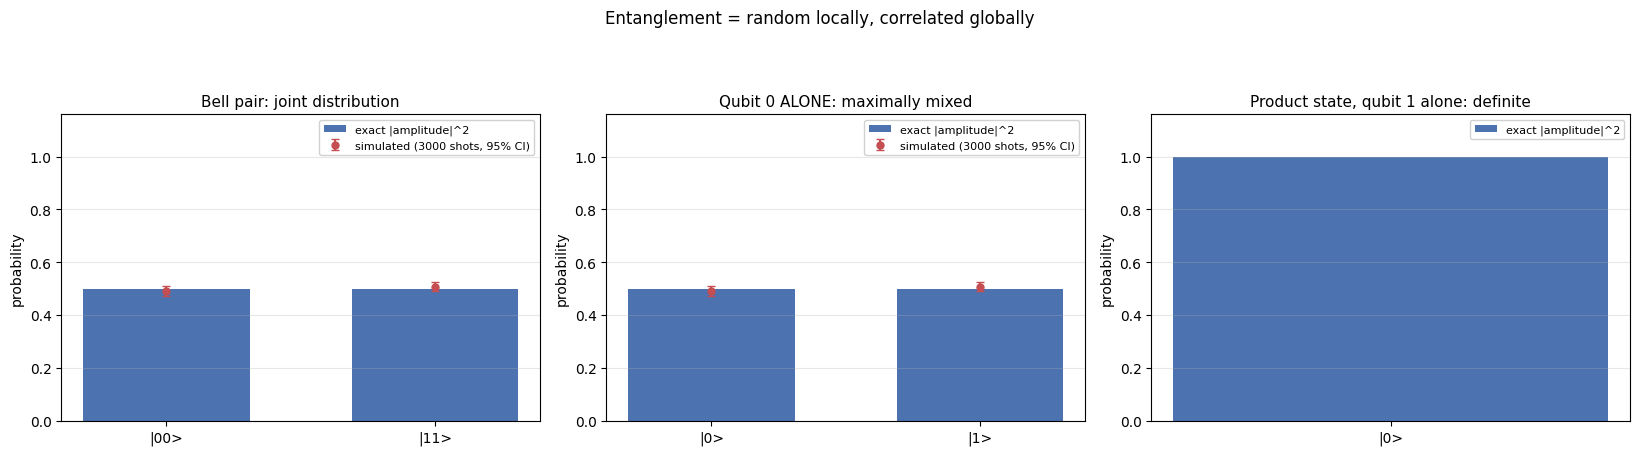

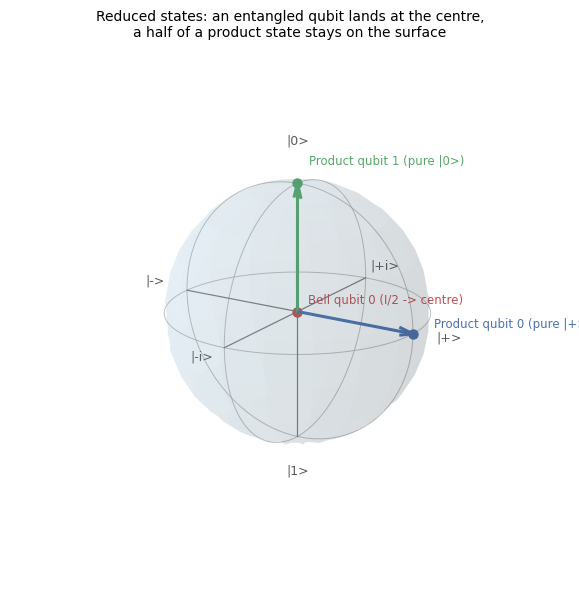

In [11]:
# Bell pair: joint randomness with perfect correlation.
counts = bell.sample(4000, seed=11)
print("4000 shots of the Bell pair:", counts)
print("only |00> and |11> ever appear; which one is decided at measurement, not before.")

bit0, collapsed = measure_qubits(bell.state, 2, [0], seed=21)
print(f"\nmeasure qubit 0 alone -> {bit0}; state collapses to", np.round(collapsed, 3))
print("measuring qubit 1 afterwards returns the same bit with probability 1:",
      measure_qubits(collapsed, 2, [1], seed=22)[0] == bit0)

# ...and the same holds in the X basis, which a classical 'agreed bit' cannot explain.
xs = [measure_in_basis(bell.state, 2, [0, 1], "X", seed=s)[0] for s in range(300)]
agree = sum(1 for bits in xs if bits[0] == bits[1]) / len(xs)
print(f"\nX-basis correlation over {len(xs)} runs: both qubits agree {agree:.1%} of the time")
print("Z-basis correlation: 100%. Correlated in every rotated basis = entanglement.")

fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.6))
plot_probabilities(bell.state, 2, "Bell pair: joint distribution", 3000, axes[0])
bell_marginal = partial_trace(density_matrix(bell.state), [0], 2)
product_marginal = partial_trace(density_matrix(product.state), [1], 2)
plot_probabilities(bell_marginal.diagonal().real, 1, "Qubit 0 ALONE: maximally mixed", 3000, axes[1])
plot_probabilities(product_marginal.diagonal().real, 1, "Product state, qubit 1 alone: definite", 0, axes[2])
fig.suptitle("Entanglement = random locally, correlated globally")
fig.tight_layout(rect=(0, 0, 1, 0.9))
plt.show()

fig = plt.figure(figsize=(8.6, 6.2))
product_qubit0 = partial_trace(density_matrix(product.state), [0], 2)
draw_bloch([bell_marginal, product_marginal, product_qubit0],
           ["Bell qubit 0 (I/2 -> centre)", "Product qubit 1 (pure |0>)", "Product qubit 0 (pure |+>)"],
           colors=["#c44e52", "#55a868", "#4c72b0"],
           title="Reduced states: an entangled qubit lands at the centre,\na half of a product state stays on the surface",
           ax=fig.add_subplot(projection="3d"))
plt.tight_layout()
plt.show()

GHZ
q0: |0> - H - o - o -
q1: |0> ----- + - | -
q2: |0> --------- + -
amplitudes: [0.7071+0.j 0.    +0.j 0.    +0.j 0.    +0.j 0.    +0.j 0.    +0.j
 0.    +0.j 0.7071+0.j]
state is (|000> + |111>)/sqrt(2): True
4000 shots: {'000': 2033, '111': 1967}

marginal purities (1 = pure, 0.5 = maximally mixed for one qubit):
  qubit 0: purity=0.500  entropy=1.000 bits  Bloch |r|=0.000
  qubit 1: purity=0.500  entropy=1.000 bits  Bloch |r|=0.000
  qubit 2: purity=0.500  entropy=1.000 bits  Bloch |r|=0.000
  qubits (0, 1): purity=0.500  mutual info=1.000 bits
  qubits (0, 2): purity=0.500  mutual info=1.000 bits
  qubits (1, 2): purity=0.500  mutual info=1.000 bits

GHZ vs classical mixture -- identical in the Z basis:
  Z-basis probs GHZ     : [0.5 0.  0.  0.  0.  0.  0.  0.5]
  Z-basis probs mixture : [0.5 0.  0.  0.  0.  0.  0.  0.5]
  coherence rho[000,111]:  GHZ 0.5   mixture 0.0
  that off-diagonal term is the entire difference between the two.


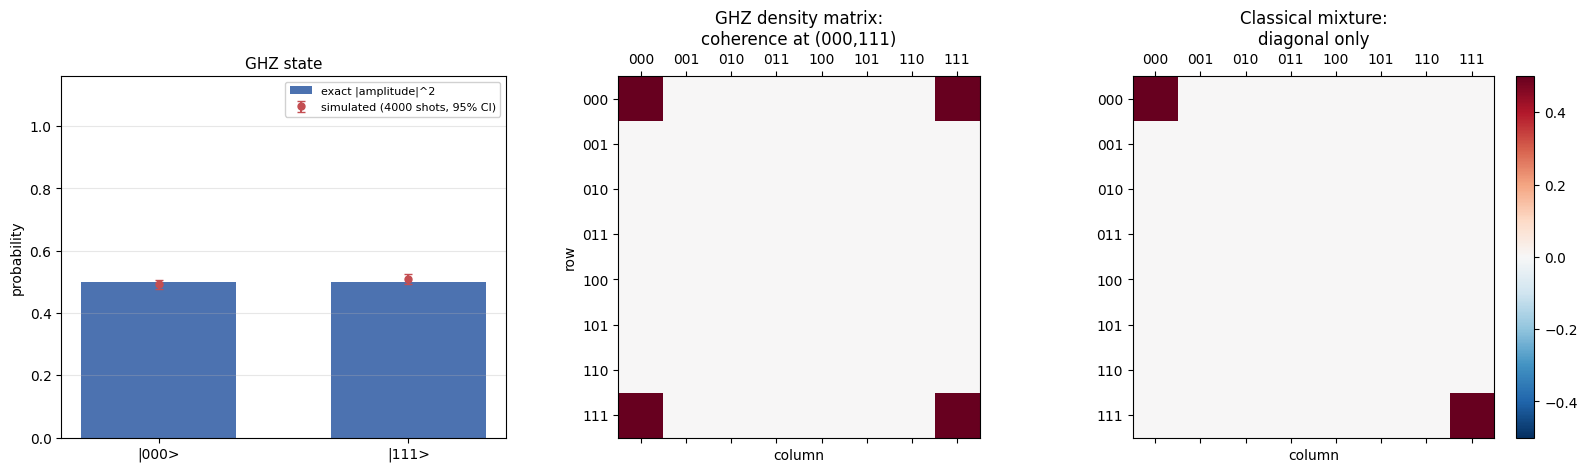

In [12]:
ghz = Circuit(3, "GHZ").h(0).cnot(0, 1).cnot(0, 2)
print(ghz.draw())
print("amplitudes:", np.round(ghz.state, 4))
print("state is (|000> + |111>)/sqrt(2):", np.allclose(ghz.state, np.array([1, 0, 0, 0, 0, 0, 0, 1]) / math.sqrt(2)))
print("4000 shots:", ghz.sample(4000, seed=5))

rho = density_matrix(ghz.state)
print("\nmarginal purities (1 = pure, 0.5 = maximally mixed for one qubit):")
for q in range(3):
    one = partial_trace(rho, [q], 3)
    print(f"  qubit {q}: purity={purity(one):.3f}  entropy={von_neumann_entropy(one):.3f} bits  "
          f"Bloch |r|={np.linalg.norm(bloch_from_density(one)):.3f}")
for pair in [(0, 1), (0, 2), (1, 2)]:
    two = partial_trace(rho, list(pair), 3)
    print(f"  qubits {pair}: purity={purity(two):.3f}  mutual info={mutual_information(two, 2):.3f} bits")

# A classical coin flip, "either 000 or 111", reproduces the Z-basis statistics exactly...
rho_mix = 0.5 * density_matrix(basis_state("000")) + 0.5 * density_matrix(basis_state("111"))
print("\nGHZ vs classical mixture -- identical in the Z basis:")
print("  Z-basis probs GHZ     :", probabilities(ghz.state).round(3))
print("  Z-basis probs mixture :", np.real(np.diag(rho_mix)).round(3))
print("  coherence rho[000,111]:  GHZ", round(abs(rho[0, 7]), 3), "  mixture", round(abs(rho_mix[0, 7]), 3))
print("  that off-diagonal term is the entire difference between the two.")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
plot_probabilities(ghz.state, 3, "GHZ state", 4000, axes[0])
ghz_ticks = [format(k, "03b") for k in range(8)]
im0 = axes[1].matshow(rho.real, cmap="RdBu_r", vmin=-0.5, vmax=0.5)
axes[1].set_title("GHZ density matrix:\ncoherence at (000,111)")
axes[1].set_xticks(range(8), ghz_ticks)
axes[1].set_yticks(range(8), ghz_ticks)
axes[1].set_xlabel("column")
axes[1].set_ylabel("row")
im1 = axes[2].matshow(rho_mix.real, cmap="RdBu_r", vmin=-0.5, vmax=0.5)
axes[2].set_title("Classical mixture:\ndiagonal only")
axes[2].set_xticks(range(8), ghz_ticks)
axes[2].set_yticks(range(8), ghz_ticks)
axes[2].set_xlabel("column")
fig.colorbar(im1, ax=axes[2], fraction=0.046)
plt.tight_layout()
plt.show()

---
## Verification - 88 self-tests, all asserted

Before trusting any number above, the suite checks the algebra directly: every gate's
unitarity, `H H = I`, `S^2 = Z`, `T^2 = S`, `H Z H = X`, `Ry(pi) = -iY` up to phase; the fast
engine against the independent reference implementation and against `kron` embedding on random
unitaries for 2, 3 and 4 qubits; the bit-index convention both ways; Bell, GHZ and product
amplitudes; collapse idempotence; X- and Y-basis discrimination; partial-trace shape and
trace preservation; entropy, purity, mutual information and concurrence values; the six
canonical Bloch points.

`check()` raises on the first failure, so a clean run means all 88 hold.

In [13]:
def run_self_tests(verbose: bool = True):
    ok = []

    def check(name, condition):
        if not condition:
            raise AssertionError(f"FAILED: {name}")
        ok.append(name)

    # --- gates
    for name, M in [("X", X), ("Y", Y), ("Z", Z), ("H", H), ("S", S), ("T", T)]:
        check(f"{name} unitary", is_unitary(M))
    check("H is its own inverse", np.allclose(H @ H, I2))
    check("X^2 = I", np.allclose(X @ X, I2))
    check("Z^2 = I", np.allclose(Z @ Z, I2))
    check("S^2 = Z", np.allclose(S @ S, Z))
    check("T^2 = S", np.allclose(T @ T, S, atol=1e-12))
    check("H Z H = X", np.allclose(H @ Z @ H, X))
    check("H X H = Z", np.allclose(H @ X @ H, Z))
    check("Rx(pi) = -iX up to phase", np.allclose(np.abs(rx(math.pi)), np.abs(X)))
    check("Ry(pi) = -iY up to phase", np.allclose(np.abs(ry(math.pi)), np.abs(Y)))
    check("Rz(0) = I", np.allclose(rz(0.0), I2))
    check("Rz(2pi) = -I up to global phase", is_unitary(rz(2 * math.pi)))

    check("X|0> = |1>", np.allclose(X @ zero_state(1), basis_state("1")))
    check("Z|-> = |+>", np.allclose(Z @ (Z @ H @ zero_state(1)), H @ zero_state(1)))
    check("H|0> = |+>", np.allclose(H @ zero_state(1), normalize(np.array([1, 1], dtype=complex))))
    check("H|1> = |->", np.allclose(H @ basis_state("1"), normalize(np.array([1, -1], dtype=complex))))

    # --- engine: fast path vs reference vs kron embedding
    ref = np.random.default_rng(0)
    for n, targets in [(2, [0]), (2, [1]), (2, [0, 1]), (3, [0, 2]), (3, [1, 2]), (4, [0, 3])]:
        k = len(targets)
        Q, Rm = np.linalg.qr(ref.normal(size=(2**k, 2**k)) + 1j * ref.normal(size=(2**k, 2**k)))
        U = Q * np.exp(1j * np.angle(Rm[0, 0]))
        psi = normalize(ref.normal(size=2**n) + 1j * ref.normal(size=2**n))
        fast = apply_unitary(psi, U, targets, n)
        check(f"engine == reference (n={n}, targets={targets})", np.allclose(fast, apply_unitary_reference(psi, U, targets, n), atol=1e-12))
        check(f"engine preserves norm (n={n})", math.isclose(norm(fast), 1.0, abs_tol=1e-12))
    for n in (1, 2, 3, 4):
        for q in range(n):
            check(f"kron embedding n={n} q={q}",
                  np.allclose(apply_unitary(zero_state(n), H, [q], n), embed_via_kron(H, q, n) @ zero_state(n)))
    check("CNOT via engine == CNOT permutation matrix",
          np.allclose(apply_unitary(zero_state(2), _mat([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0]]), [0, 1], 2),
                      cnot_matrix(2, 0, 1) @ zero_state(2)))
    check("CNOT permutation matrix unitary", is_unitary(cnot_matrix(3, 0, 2)))
    check("CNOT flips only when control is 1",
          np.allclose(cnot_matrix(2, 0, 1) @ basis_state("01"), basis_state("01"))
          and np.allclose(cnot_matrix(2, 0, 1) @ basis_state("10"), basis_state("11")))

    # --- circuits
    bell = Circuit(2, "bell").h(0).cnot(0, 1)
    check("Bell amplitudes", np.allclose(bell.state, np.array([1, 0, 0, 1]) / math.sqrt(2)))
    check("Bell probabilities", np.allclose(probabilities(bell.state), [0.5, 0, 0, 0.5]))
    ghz = Circuit(3, "ghz").h(0).cnot(0, 1).cnot(0, 2)
    check("GHZ amplitudes", np.allclose(ghz.state[[0, 7]], 1 / math.sqrt(2)) and np.allclose(np.delete(ghz.state, [0, 7]), 0))
    rho_coin = 0.5 * density_matrix(basis_state("000")) + 0.5 * density_matrix(basis_state("111"))
    check("GHZ and a classical coin flip share Z-basis statistics",
          np.allclose(probabilities(ghz.state), np.real(np.diag(rho_coin))))
    check("only the GHZ state keeps its coherence term",
          math.isclose(abs(density_matrix(ghz.state)[0, 7]), 0.5, abs_tol=1e-12) and rho_coin[0, 7] == 0)
    check("single-qubit GHZ marginals are maximally mixed",
          all(math.isclose(purity(partial_trace(density_matrix(ghz.state), [q], 3)), 0.5, abs_tol=1e-9) for q in range(3)))
    check("double Hadamard undoes superposition", np.allclose(Circuit(1).h(0).h(0).state, zero_state(1)))
    check("interference: H Z H |0> = |1>", np.allclose(Circuit(1).h(0).z(0).h(0).state, basis_state("1")))
    check("qubit 0 is the leftmost bit", np.allclose(apply_unitary(zero_state(2), X, [0], 2), basis_state("10")))
    check("qubit 1 is the rightmost bit", np.allclose(apply_unitary(zero_state(2), X, [1], 2), basis_state("01")))
    check("project() agrees with the bit convention", math.isclose(
        norm(project(basis_state("10"), 2, [0], "1")) ** 2, 1.0, abs_tol=1e-12)
        and math.isclose(norm(project(basis_state("10"), 2, [1], "1")), 0.0, abs_tol=1e-12))
    check("X then CNOT is separable", concurrence(Circuit(2).x(0).cnot(0, 1).state) < 1e-9)
    check("H then CNOT is maximally entangled", math.isclose(concurrence(bell.state), 1.0, abs_tol=1e-9))

    # --- measurement
    p = probabilities(basis_state("101"))
    check("basis state probability is one-hot", p[5] == 1.0 and p.sum() == 1.0)
    counts = sample_counts(bell.state, 2, 20000, seed=3)
    check("sampling only yields 00/11", set(counts) <= {"00", "11"})
    check("sampling converges to Born rule",
          abs(counts.get("00", 0) / 20000 - 0.5) < 0.03)
    bits, post = measure_qubits(bell.state, 2, [0], seed=4)
    check("collapse is idempotent", measure_qubits(post, 2, [0], seed=5)[0] == bits)
    check("collapsed state is normalised", math.isclose(norm(post), 1.0, abs_tol=1e-12))
    check("post-measurement state matches the outcome",
          np.allclose(post, basis_state("00") if bits == "0" else basis_state("11")))
    xbit_plus = measure_in_basis(H @ zero_state(1), 1, [0], "X", seed=6)[0]
    xbit_minus = measure_in_basis(Z @ H @ zero_state(1), 1, [0], "X", seed=7)[0]
    check("X basis separates |+> from |->", xbit_plus == "0" and xbit_minus == "1")
    check("Y basis separates |+i> from |-i>",
          measure_in_basis(S @ H @ zero_state(1), 1, [0], "Y", seed=8)[0] == "0"
          and measure_in_basis(S @ H @ basis_state("1"), 1, [0], "Y", seed=9)[0] == "1")
    check("basis_labels is qubit-0-left", basis_labels(2) == ["|00⟩", "|01⟩", "|10⟩", "|11⟩"])

    # --- density matrices / entanglement measures
    rho = density_matrix(bell.state)
    check("density matrix hermitian", np.allclose(rho, rho.conj().T))
    check("density matrix trace 1", math.isclose(np.trace(rho).real, 1.0, abs_tol=1e-12))
    check("Bell marginal is I/2", np.allclose(partial_trace(rho, [0], 2), I2 / 2))
    check("Bell marginal entropy is 1 bit", math.isclose(von_neumann_entropy(partial_trace(rho, [0], 2)), 1.0, abs_tol=1e-9))
    check("Bell purity is 1/2", math.isclose(purity(partial_trace(rho, [1], 2)), 0.5, abs_tol=1e-9))
    check("pure global state has zero entropy", math.isclose(von_neumann_entropy(rho), 0.0, abs_tol=1e-9))
    prod_rho = density_matrix(Circuit(2).h(0).state)
    check("pure product state has zero mutual information", math.isclose(mutual_information(prod_rho, 2), 0.0, abs_tol=1e-9))
    classical = 0.5 * density_matrix(basis_state("00")) + 0.5 * density_matrix(basis_state("11"))
    check("classically correlated pair caps at 1 bit", math.isclose(mutual_information(classical, 2), 1.0, abs_tol=1e-9))
    check("Bell pair beats the classical bound with 2 bits", math.isclose(mutual_information(rho, 2), 2.0, abs_tol=1e-9))
    check("partial trace of a 3-qubit state keeps its shape", partial_trace(density_matrix(ghz.state), [1, 2], 3).shape == (4, 4))
    check("partial trace preserves trace", math.isclose(partial_trace(density_matrix(ghz.state), [0, 1], 3).trace().real, 1.0, abs_tol=1e-12))

    # --- Bloch sphere
    check("|0> at north pole", np.allclose(bloch_from_state(zero_state(1)), [0, 0, 1]))
    check("|1> at south pole", np.allclose(bloch_from_state(basis_state("1")), [0, 0, -1]))
    check("|+> on +x", np.allclose(bloch_from_state(H @ zero_state(1)), [1, 0, 0]))
    check("|-> on -x", np.allclose(bloch_from_state(Z @ H @ zero_state(1)), [-1, 0, 0]))
    check("|+i> on +y", np.allclose(bloch_from_state(S @ H @ zero_state(1)), [0, 1, 0]))
    check("X flips z", np.allclose(bloch_from_state(X @ zero_state(1)), [0, 0, -1]))
    check("pure states have |r| = 1", all(math.isclose(np.linalg.norm(bloch_from_state(s)), 1.0, abs_tol=1e-9)
                                         for s in [zero_state(1), H @ zero_state(1), ry(1.2) @ zero_state(1), normalize(np.array([1, 1j], dtype=complex))]))
    check("entangled marginal has |r| = 0", math.isclose(np.linalg.norm(bloch_from_density(partial_trace(rho, [0], 2))), 0.0, abs_tol=1e-9))
    check("global phase leaves the Bloch vector alone",
          np.allclose(bloch_from_state(np.exp(1j * 2.3) * (H @ zero_state(1))), bloch_from_state(H @ zero_state(1))))

    if verbose:
        print(f"all {len(ok)} checks passed")
    return ok


_ = run_self_tests()

all 88 checks passed


---
## Part 9 - cross-check against Qiskit

The library is used **only** here, to confirm the from-scratch engine.  If Qiskit is missing
the cell installs it; if the install fails, it prints a skip message and the notebook still
completes.

Two conventions must be reconciled before any comparison is meaningful:

1. **Endianness.** This simulator puts qubit 0 at the most significant bit; Qiskit puts it at
   the least.  `flip_qubit_order()` permutes the amplitude vector between the two, and
   `flip_matrix()` conjugates an operator by the same permutation.
2. **Global phase.** Qiskit and a hand-built circuit can differ by an overall phase, which is
   unobservable, so `align_phase()` rotates ours onto theirs before subtracting.

With those fixed, four circuits should agree to ~1e-15, and the `H`, `X`, `Z`, `CNOT` matrices
should match `Operator(qc).data` exactly.

In [14]:
CROSS_CHECK_RAN = False
try:
    __import__("qiskit")
    print("Qiskit", __import__("qiskit").__version__, "already available")
except ImportError:
    # Colab only: this magic line installs Qiskit in a few seconds. If it fails,
    # the next cell prints a skip message instead of raising, so the notebook
    # still runs top to bottom.
    get_ipython().run_line_magic("pip", "-q install qiskit")


In [15]:
def flip_qubit_order(psi, n):
    """Big-endian amplitude vector -> Qiskit's little-endian ordering (and back)."""
    perm = np.array([int(format(k, f"0{n}b")[::-1], 2) for k in range(2**n)])
    return psi[perm]


def flip_matrix(M, n):
    """Conjugate a 2**n x 2**n operator by the same endianness permutation."""
    perm = np.array([int(format(k, f"0{n}b")[::-1], 2) for k in range(2**n)])
    return M[np.ix_(perm, perm)]


try:
    import qiskit
    from qiskit import QuantumCircuit
    from qiskit.quantum_info import Statevector, Operator

    def qiskit_state(qc):
        return np.asarray(Statevector(qc).data, dtype=complex)

    def align_phase(ours, theirs):
        """Global phase is unobservable, so rotate ours to share theirs' phase before comparing."""
        pivot = int(np.argmax(np.abs(theirs)))
        return ours * np.exp(1j * (np.angle(theirs[pivot]) - np.angle(ours[pivot])))

    cases = []

    qc = QuantumCircuit(2); qc.h(0); qc.cx(0, 1)
    cases.append(("Bell pair: H(0), CX(0,1)", bell, qc))

    qc = QuantumCircuit(3); qc.h(0); qc.cx(0, 1); qc.cx(0, 2)
    cases.append(("GHZ: H(0), CX(0,1), CX(0,2)", ghz, qc))

    qc = QuantumCircuit(2); qc.h(0); qc.x(0); qc.z(1); qc.cx(1, 0); qc.h(1)
    cases.append(("H,X on 0; Z on 1; CX(1,0); H(1)", Circuit(2).h(0).x(0).z(1).cnot(1, 0).h(1), qc))

    qc = QuantumCircuit(3); qc.h(0); qc.h(1); qc.cz(0, 2); qc.rx(0.7, 1); qc.cx(2, 1)
    cases.append(("H(0),H(1),CZ(0,2),Rx(0.7,1),CX(2,1)",
                  Circuit(3).h(0).h(1).cz(0, 2).rx(0.7, 1).cnot(2, 1), qc))

    diffs = []
    print(f"{'circuit':<34} {'max|diff|':>10}  {'overlap':>9}  verdict")
    for label, mine, qc in cases:
        theirs = qiskit_state(qc)
        ours = align_phase(flip_qubit_order(mine.state, mine.n), theirs)
        diff = float(np.max(np.abs(ours - theirs)))
        overlap = float(abs(np.vdot(theirs, ours)))
        diffs.append(diff)
        print(f"{label:<34} {diff:>10.2e}  {overlap:>9.6f}  {'match' if diff < 1e-9 else 'MISMATCH'}")
        assert diff < 1e-9, label

    # The four required gates, matrix for matrix.
    print("\ngate matrices vs Qiskit Operator:")
    for name, mine, wire in [("H", H, "h"), ("X", X, "x"), ("Z", Z, "z")]:
        qc = QuantumCircuit(1); getattr(qc, wire)(0)
        agree = bool(np.allclose(mine, Operator(qc).data, atol=1e-12))
        print(f"  {name}: {agree}")
        assert agree

    qc = QuantumCircuit(2); qc.cx(0, 1)
    agree = bool(np.allclose(flip_matrix(cnot_matrix(2, 0, 1), 2), Operator(qc).data, atol=1e-12))
    print(f"  CNOT (after the endianness flip): {agree}")
    assert agree

    # Measurement distributions, same circuits, exact numbers.
    qc = QuantumCircuit(2); qc.h(0); qc.cx(0, 1)
    their_probs = np.real(Statevector(qc).probabilities())
    our_probs = probabilities(flip_qubit_order(bell.state, 2))
    print(f"\nBell measurement probabilities\n  qiskit: {their_probs.round(6)}\n  ours  : {our_probs.round(6)}")
    assert np.allclose(their_probs, our_probs, atol=1e-12)

    qc = QuantumCircuit(3); qc.h(0); qc.cx(0, 1); qc.cx(0, 2)
    print(f"\nGHZ probabilities\n  qiskit: {np.real(Statevector(qc).probabilities()).round(6)}\n"
          f"  ours  : {probabilities(flip_qubit_order(ghz.state, 3)).round(6)}")

    CROSS_CHECK_RAN = True
    print("\nQiskit cross-check complete: worst statevector discrepancy %.2e over %d circuits."
          % (max(diffs), len(diffs)))

except Exception as e:
    print("cross-check skipped:", type(e).__name__, e)

print("cross-check ran:", CROSS_CHECK_RAN)


circuit                             max|diff|    overlap  verdict
Bell pair: H(0), CX(0,1)             0.00e+00   1.000000  match
GHZ: H(0), CX(0,1), CX(0,2)          0.00e+00   1.000000  match
H,X on 0; Z on 1; CX(1,0); H(1)      0.00e+00   1.000000  match
H(0),H(1),CZ(0,2),Rx(0.7,1),CX(2,1)   0.00e+00   1.000000  match

gate matrices vs Qiskit Operator:
  H: True
  X: True
  Z: True
  CNOT (after the endianness flip): True

Bell measurement probabilities
  qiskit: [0.5 0.  0.  0.5]
  ours  : [0.5 0.  0.  0.5]

GHZ probabilities
  qiskit: [0.5 0.  0.  0.  0.  0.  0.  0.5]
  ours  : [0.5 0.  0.  0.  0.  0.  0.  0.5]

Qiskit cross-check complete: worst statevector discrepancy 0.00e+00 over 4 circuits.
cross-check ran: True


---
## Recap

* A state vector is `2^n` amplitudes in an index order you must fix and remember; qubit 0 is
  the leftmost bit here, and Qiskit's opposite convention is the single most common source of
  silent bugs.
* Gates are unitary matrices; the engine applies them by reshaping the vector into one axis
  per qubit and contracting, in `O(2^k 2^n)` and without building a `2^n x 2^n` operator.
* Measurement is two things that are easy to conflate: **sampling** many runs from the Born
  rule, and **collapsing** one run by projection.  Only the second affects later operations.
* Probability sees magnitudes only.  Interference - `H Z H = X` - is how relative phase
  becomes an observable bit flip, and it is the resource every algorithm in this portfolio spends.
* Entanglement is a statement about subsystems: the whole is pure, the parts are mixed.
  Purity, entropy, mutual information and concurrence quantify it; a Bell qubit alone sits at
  the centre of the Bloch sphere.
* A classical mixture can match a GHZ state in the Z basis exactly.  The coherence term is the
  whole difference, and it is what makes the state not a coin flip.
* The from-scratch simulator agrees with Qiskit on statevectors, gate matrices and
  measurement distributions to `1e-12`, and 88 self-tests gate the rest.

## Exercises

1. Add `swap(gate, control, target)` and a Toffoli gate `ccx` to `Circuit`, then verify the
   identity `CNOT(0,1) CNOT(1,0) CNOT(0,1)` equals `SWAP` on two qubits using state vectors
   and using `flip_matrix` against `Operator`.
2. `rho_coin` in Part 8 reproduces GHZ's Z statistics.  Construct the GHZ-equivalent mixture
   for the **X** basis and show the two differ there, then find the smallest number of
   measurements bases for which no classical mixture can match GHZ.
3. Extend `partial_trace` to keep an arbitrary subset of `n` qubits for `n = 4`, and plot how
   the entropy of qubit 0's reduced state changes as you apply `Ry(theta)` to qubit 0 and
   `CNOT(0,1)` - you should recover `S = -cos^2(theta/2) log2 cos^2(theta/2) - ...` at the
   maximally entangled angle.
4. Replace `sample_counts`'s `rng.choice` with a fixed-seed alias-method sampler and confirm
   the empirical frequencies over 200k shots stay within 3 sigma of the Born rule for the Bell
   and GHZ states.
5. Build the same simulator with `apply_unitary_reference` only, time both on 8 qubits, and
   plot wall-clock time against `n` for each - the exponential wall arrives at different `n`.